In [1]:
import os
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASET_PATH = Path("../data/NEU-DET")

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("Dataset path:", DATASET_PATH.resolve())
print("Dataset exists:", DATASET_PATH.exists())

Dataset path: D:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\data\NEU-DET
Dataset exists: True


In [2]:
for folder in [
    "train/images",
    "train/annotations",
    "validation/images",
    "validation/annotations"
]:
    path = DATASET_PATH / folder

    print(
        folder,
        "Exists:", path.exists(),
        "Files:", len(list(path.rglob("*"))) if path.exists() else 0
    )

train/images Exists: True Files: 1446
train/annotations Exists: True Files: 1439
validation/images Exists: True Files: 366
validation/annotations Exists: True Files: 361


In [3]:
records = []

for split in ["train", "validation"]:

    image_root = DATASET_PATH / split / "images"

    for class_name in CLASS_NAMES:

        class_path = image_root / class_name

        if not class_path.exists():
            print("Missing class folder:", class_path)
            continue

        images = list(class_path.glob("*.jpg"))

        records.append({
            "split": split,
            "class": class_name,
            "image_count": len(images)
        })

df = pd.DataFrame(records)

display(df)

,split,class,image_count
0,train,crazing,240
1,train,inclusion,240
2,train,patches,240
3,train,pitted_surface,240
4,train,rolled-in_scale,240
5,train,scratches,240
6,validation,crazing,60
7,validation,inclusion,60
8,validation,patches,60
9,validation,pitted_surface,60


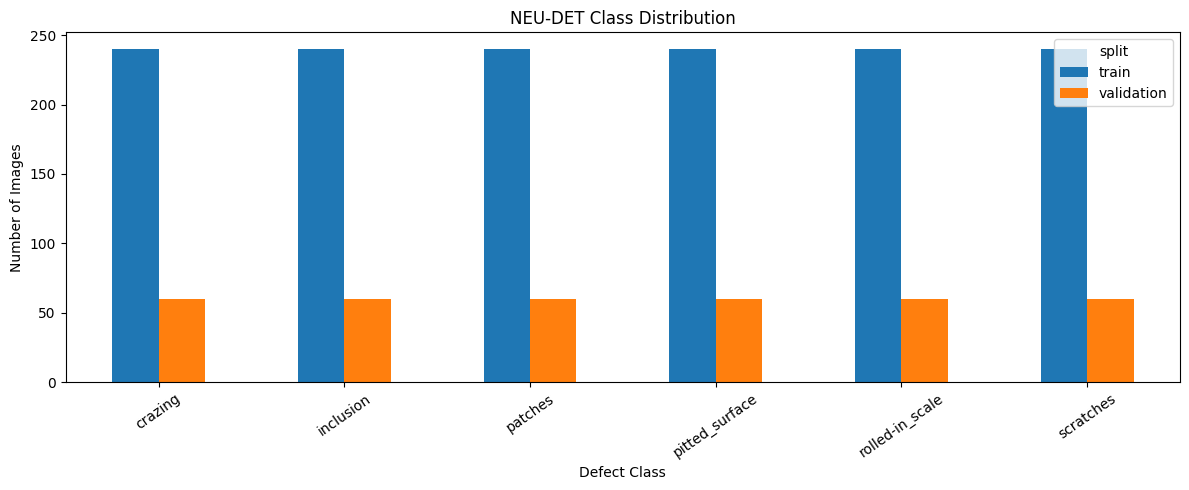

In [4]:
pivot = df.pivot(
    index="class",
    columns="split",
    values="image_count"
).fillna(0)

pivot.plot(kind="bar", figsize=(12, 5))

plt.title("NEU-DET Class Distribution")
plt.xlabel("Defect Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [5]:
image_records = []

for split in ["train", "validation"]:

    image_root = DATASET_PATH / split / "images"

    for image_path in image_root.rglob("*.jpg"):

        image = cv2.imread(str(image_path))

        if image is None:
            image_records.append({
                "image": str(image_path),
                "height": None,
                "width": None,
                "status": "Unreadable"
            })
            continue

        height, width = image.shape[:2]

        image_records.append({
            "image": str(image_path),
            "height": height,
            "width": width,
            "status": "Valid"
        })

image_df = pd.DataFrame(image_records)

display(image_df.head(10))

print("\nImage dimensions:")
print(image_df.groupby(["height", "width"]).size())

print("\nUnreadable images:")
print((image_df["status"] == "Unreadable").sum())

,image,height,width,status
0,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid
1,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid
2,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid
3,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid
4,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid
5,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid
6,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid
7,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid
8,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid
9,..\data\NEU-DET\train\images\crazing\crazing_1...,200,200,Valid



Image dimensions:
height  width
200     200      1800
dtype: int64

Unreadable images:
0


In [6]:
annotation_records = []

for split in ["train", "validation"]:

    annotation_root = DATASET_PATH / split / "annotations"

    for xml_path in annotation_root.glob("*.xml"):

        try:
            root = ET.parse(xml_path).getroot()

            for obj in root.findall("object"):

                class_name = obj.findtext("name")

                box = obj.find("bndbox")

                if box is None:
                    continue

                annotation_records.append({
                    "split": split,
                    "image": root.findtext("filename"),
                    "class": class_name,
                    "xmin": float(box.findtext("xmin")),
                    "ymin": float(box.findtext("ymin")),
                    "xmax": float(box.findtext("xmax")),
                    "ymax": float(box.findtext("ymax")),
                    "xml_file": xml_path.name
                })

        except Exception as error:
            print("XML error:", xml_path, error)

annotation_df = pd.DataFrame(annotation_records)

display(annotation_df.head(10))

print("\nAnnotations:", len(annotation_df))
print("\nClass counts:")
display(annotation_df["class"].value_counts())

,split,image,class,xmin,ymin,xmax,ymax,xml_file
0,train,crazing_1.jpg,crazing,2.0,2.0,193.0,194.0,crazing_1.xml
1,train,crazing_10.jpg,crazing,60.0,20.0,194.0,69.0,crazing_10.xml
2,train,crazing_10.jpg,crazing,9.0,84.0,197.0,198.0,crazing_10.xml
3,train,crazing_100.jpg,crazing,1.0,10.0,108.0,121.0,crazing_100.xml
4,train,crazing_100.jpg,crazing,35.0,1.0,200.0,83.0,crazing_100.xml
5,train,crazing_100.jpg,crazing,120.0,109.0,196.0,198.0,crazing_100.xml
6,train,crazing_100.jpg,crazing,8.0,112.0,164.0,190.0,crazing_100.xml
7,train,crazing_101.jpg,crazing,40.0,12.0,187.0,152.0,crazing_101.xml
8,train,crazing_102.jpg,crazing,2.0,2.0,144.0,153.0,crazing_102.xml
9,train,crazing_102.jpg,crazing,150.0,85.0,199.0,178.0,crazing_102.xml



Annotations: 4189

Class counts:


class
inclusion          1011
patches             881
crazing             689
rolled-in_scale     628
scratches           548
pitted_surface      432
Name: count, dtype: int64

In [7]:
if not annotation_df.empty:

    invalid_boxes = annotation_df[
        (annotation_df["xmin"] >= annotation_df["xmax"]) |
        (annotation_df["ymin"] >= annotation_df["ymax"]) |
        (annotation_df["xmin"] < 0) |
        (annotation_df["ymin"] < 0) |
        (annotation_df["xmax"] > 200) |
        (annotation_df["ymax"] > 200)
    ]

    print("Total annotations:", len(annotation_df))
    print("Invalid bounding boxes:", len(invalid_boxes))

    display(invalid_boxes.head())

Total annotations: 4189
Invalid bounding boxes: 0


,split,image,class,xmin,ymin,xmax,ymax,xml_file
